## CL-1 Lab Assignment 5 (Group A) : Ensemble Learning
### Different voting mechanisms with AdaBoost, Gradient Tree Boosting (GBM), and XGBoost classification on the Iris dataset.

In [1]:
# Import required libraries
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.ensemble import (
    AdaBoostClassifier, GradientBoostingClassifier, VotingClassifier
)
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
csv_path = "iris.csv"

if csv_path:
    iris_df = pd.read_csv(csv_path)
    # Remove an identifier column if present.
    if "Id" in iris_df.columns:
        iris_df = iris_df.drop(columns=["Id"])
    print(f"Loaded dataset from: {csv_path}")
else:
    iris = load_iris(as_frame=True)
    iris_df = iris.frame.copy()
    iris_df["target"] = iris_df["target"].map(dict(enumerate(iris.target_names)))
    print("Iris.csv was not found; using sklearn's equivalent Iris dataset.")

display(iris_df.head())
print("\nShape:", iris_df.shape)
print("\nColumns:", list(iris_df.columns))
print("\nMissing values:\n", iris_df.isnull().sum())
print("\nClass distribution:\n", iris_df.iloc[:, -1].value_counts())

Iris.csv was not found; using sklearn's equivalent Iris dataset.


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Shape: (150, 5)

Columns: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'target']

Missing values:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Class distribution:
 target
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [3]:
# Separate features and target
target_col = "Species" if "Species" in iris_df.columns else (
    "species" if "species" in iris_df.columns else "target"
)

X = iris_df.drop(columns=[target_col])
y_raw = iris_df[target_col].astype(str)

# Keep only numeric feature columns (protects against accidental identifier columns)
X = X.select_dtypes(include=np.number)

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_raw)

print("Features:", list(X.columns))
print("Classes:", list(label_encoder.classes_))

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

Training samples: 120
Testing samples: 30


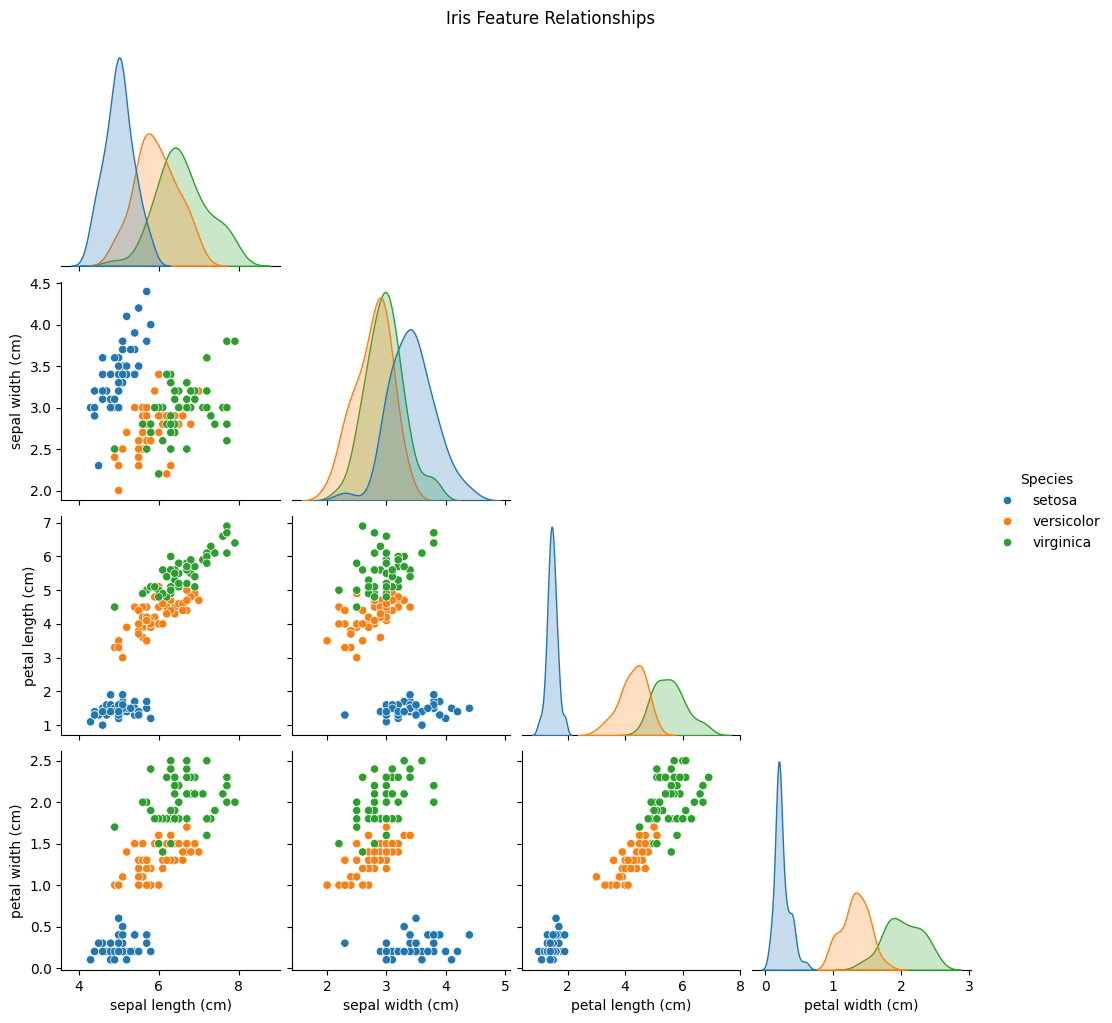

In [4]:
# Pairwise visualization of the Iris features
plot_df = X.copy()
plot_df["Species"] = y_raw.values

sns.pairplot(plot_df, hue="Species", corner=True)
plt.suptitle("Iris Feature Relationships", y=1.02)
plt.show()

In [5]:
# Model 1: AdaBoost
ada_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
    n_estimators=100,
    learning_rate=0.5,
    random_state=RANDOM_STATE
)

# Model 2: Gradient Tree Boosting (GBM)
gbm_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    random_state=RANDOM_STATE
)

# Model 3: XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="multi:softprob",
    eval_metric="mlogloss",
    num_class=3,
    random_state=RANDOM_STATE,
    n_jobs=2
)

models = {
    "AdaBoost": ada_model,
    "Gradient Boosting (GBM)": gbm_model,
    "XGBoost": xgb_model
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")

AdaBoost trained successfully.


Gradient Boosting (GBM) trained successfully.
XGBoost trained successfully.


In [6]:
def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "Predictions": y_pred
    }

evaluation_rows = []
predictions = {}

for name, model in models.items():
    result = evaluate_model(name, model, X_test, y_test)
    predictions[name] = result.pop("Predictions")
    evaluation_rows.append(result)

results_df = pd.DataFrame(evaluation_rows)
display(results_df.drop(columns=[]).style.format({
    "Accuracy": "{:.4f}",
    "Precision (macro)": "{:.4f}",
    "Recall (macro)": "{:.4f}",
    "F1-score (macro)": "{:.4f}"
}))

,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,AdaBoost,0.9667,0.9697,0.9667,0.9666
1,Gradient Boosting (GBM),0.9333,0.9333,0.9333,0.9333
2,XGBoost,0.9667,0.9697,0.9667,0.9666


In [7]:
# Detailed classification reports
for name, model in models.items():
    print("=" * 70)
    print(name)
    print("=" * 70)
    print(classification_report(
        y_test,
        predictions[name],
        target_names=label_encoder.classes_,
        zero_division=0
    ))

AdaBoost
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

Gradient Boosting (GBM)


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

XGBoost
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



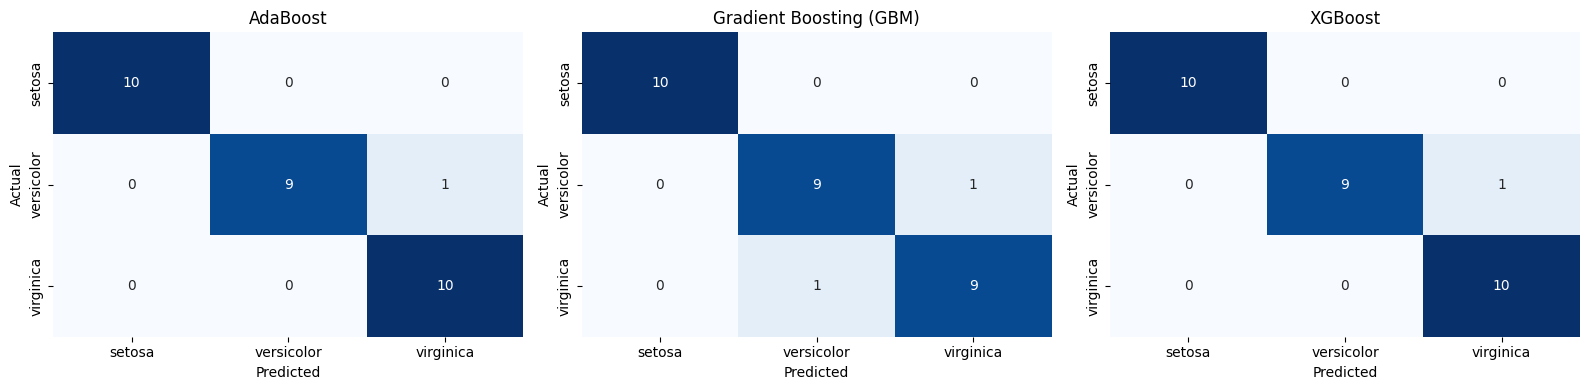

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [9]:
voting_estimators = [
    ("ada", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
        n_estimators=100, learning_rate=0.5, random_state=RANDOM_STATE
    )),
    ("gbm", GradientBoostingClassifier(
        n_estimators=100, learning_rate=0.05, max_depth=2, random_state=RANDOM_STATE
    )),
    ("xgb", XGBClassifier(
        n_estimators=100, max_depth=3, learning_rate=0.05,
        subsample=0.9, colsample_bytree=0.9,
        objective="multi:softprob", eval_metric="mlogloss",
        num_class=3, random_state=RANDOM_STATE, n_jobs=2
    ))
]

hard_voting = VotingClassifier(
    estimators=voting_estimators,
    voting="hard"
)

# Soft voting needs predict_proba, which all three classifiers provide.
soft_voting = VotingClassifier(
    estimators=voting_estimators,
    voting="soft"
)

hard_voting.fit(X_train, y_train)
soft_voting.fit(X_train, y_train)

voting_models = {
    "Hard Voting": hard_voting,
    "Soft Voting": soft_voting
}

voting_rows = []
for name, model in voting_models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    voting_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, pred, average="macro", zero_division=0)
    })

voting_results_df = pd.DataFrame(voting_rows)
display(voting_results_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision (macro)": "{:.4f}",
    "Recall (macro)": "{:.4f}",
    "F1-score (macro)": "{:.4f}"
}))

,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,Hard Voting,0.9667,0.9697,0.9667,0.9666
1,Soft Voting,0.9333,0.9333,0.9333,0.9333


,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,AdaBoost,0.9667,0.9697,0.9667,0.9666
1,Gradient Boosting (GBM),0.9333,0.9333,0.9333,0.9333
2,XGBoost,0.9667,0.9697,0.9667,0.9666
3,Hard Voting,0.9667,0.9697,0.9667,0.9666
4,Soft Voting,0.9333,0.9333,0.9333,0.9333


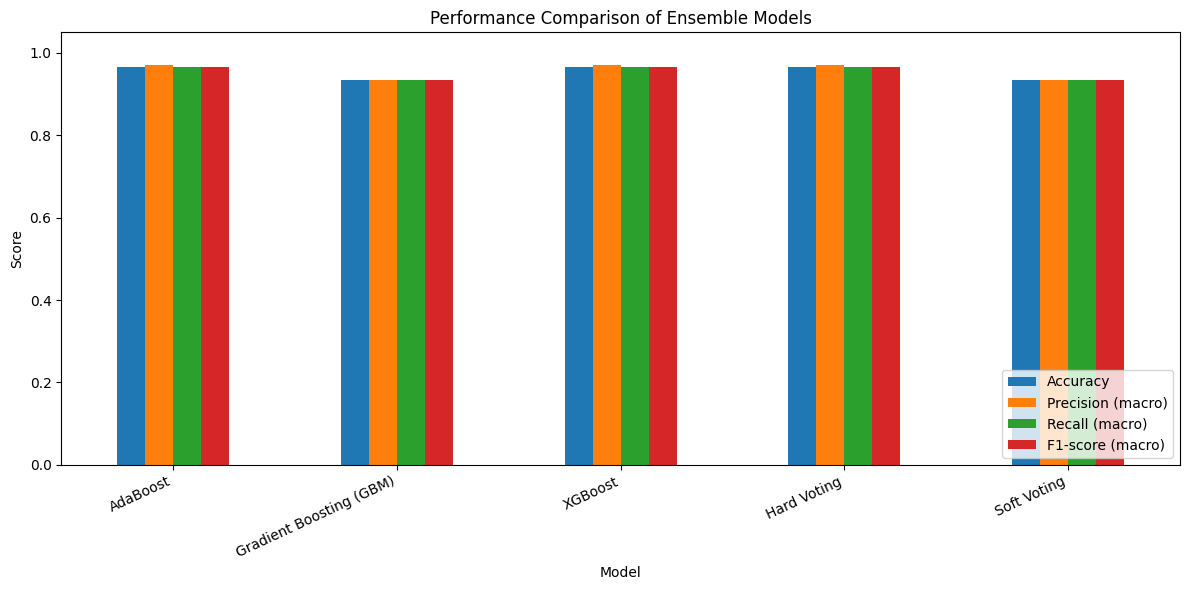

In [10]:
all_results = pd.concat([
    results_df.drop(columns=["Predictions"], errors="ignore"),
    voting_results_df
], ignore_index=True)

display(all_results.style.format({
    "Accuracy": "{:.4f}",
    "Precision (macro)": "{:.4f}",
    "Recall (macro)": "{:.4f}",
    "F1-score (macro)": "{:.4f}"
}))

# Metric comparison plot
metric_cols = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]
ax = all_results.set_index("Model")[metric_cols].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1.05)
)
ax.set_title("Performance Comparison of Ensemble Models")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

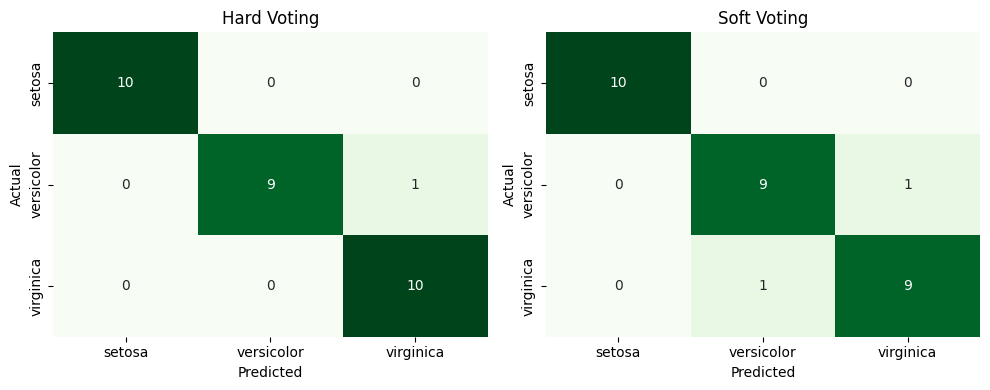

In [11]:
# Confusion matrices for the two voting ensembles
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, name in zip(axes, ["Hard Voting", "Soft Voting"]):
    cm = confusion_matrix(y_test, predictions[name])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Greens", cbar=False,
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()